# Семинар. Seq2seq и механизм внимания

**Курс:** «Интеллектуальный анализ текстов: от статистических моделей языка до языковых агентов». Семинар к лекции «Нейронные сети: от нейрона до seq2seq с вниманием» (модуль 2).

## О чём блокнот

Модель «последовательность в последовательность» (sequence-to-sequence, seq2seq) получает на вход одну последовательность и порождает другую, возможно другой длины. Так устроены машинный перевод, реферирование, ответы на вопросы. В блокноте такая модель строится из двух рекуррентных сетей и обучается на учебной задаче: перевести дату из записи «12 ноября 2026» в запись «2026-11-12». Затем к модели добавляется механизм внимания, и обе модели сравниваются. Блокнот выполняется на процессоре примерно за три минуты.

| Часть | Содержание |
|---|---|
| 1 | Задача и данные |
| 2 | Кодировщик и декодировщик |
| 3 | Обучение с принудительной подачей ответа и жадный вывод |
| 4 | Узкое место: один вектор на весь вход |
| 5 | Внимание: числовой пример и модель |
| 6 | Карты внимания |
| 7 | Длинные последовательности: разворот строки цифр |

In [1]:
import json
import random
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import torch
import torch.nn as nn
import torch.nn.functional as F

warnings.filterwarnings("ignore")
torch.set_num_threads(4)

SEED = 42
BLUE, ORANGE, MUTED, GRID = "#2a78d6", "#eb6834", "#6b7280", "#e5e7eb"
GREEN, VIOLET = "#1baf7a", "#6250d6"
# расходящаяся шкала: синий (класс 0), серый (0.5), оранжевый (класс 1)
DIV = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#cfe0f7", "#f0f0ee", "#f9d5c5", "#eb6834"])
SEQ = LinearSegmentedColormap.from_list("seq", ["#f6f9fe", "#cde2fb", "#6da7ec", "#256abf", "#0d366b"])
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 11, "axes.titleweight": "bold"})


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
set_seed()
print("Готово, PyTorch", torch.__version__)

Готово, PyTorch 2.10.0+cpu


## Часть 1. Задача и данные

Вход и выход рассматриваются как последовательности символов. Модель не знает, что такое день, месяц и год: ей даны только пары строк. Чтобы решить задачу, нужно переставить части даты, заменить название месяца его номером и дописать ноль к однозначному числу.

Задача учебная, зато в ней есть все свойства перевода: вход и выход разной длины, порядок частей меняется, одному слову входа соответствует несколько символов выхода.

К выходной строке добавляются два служебных символа. С символа начала `<bos>` декодировщик начинает работу. Символом конца `<eos>` он сообщает, что строка закончена.

In [2]:
PAD, BOS, EOS = 0, 1, 2      # служебные символы: заполнитель, начало и конец последовательности


class CharVocab:
    def __init__(self, texts):
        self.chars = ["<pad>", "<bos>", "<eos>"] + sorted({c for t in texts for c in t})
        self.index = {c: i for i, c in enumerate(self.chars)}

    def __len__(self):
        return len(self.chars)

    def encode(self, text):
        return [self.index[c] for c in text if c in self.index]

    def decode(self, ids):
        return "".join(self.chars[i] for i in ids if i > EOS)


def pad_batch(seqs):
    # Выравнивает последовательности номеров до общей длины заполнителем PAD.
    out = torch.full((len(seqs), max(len(s) for s in seqs)), PAD, dtype=torch.long)
    for i, s in enumerate(seqs):
        out[i, :len(s)] = torch.tensor(s)
    return out

In [3]:
MONTHS = ["января", "февраля", "марта", "апреля", "мая", "июня", "июля", "августа", "сентября", "октября",
          "ноября", "декабря"]


def date_pair(rng):
    # Случайная дата в двух записях: «12 ноября 2026» и «2026-11-12».
    day, month, year = rng.randint(1, 28), rng.randint(1, 12), rng.randint(1950, 2049)
    return f"{day} {MONTHS[month - 1]} {year}", f"{year}-{month:02d}-{day:02d}"


def reverse_pair(rng, min_len=3, max_len=20, length=None):
    # Случайная строка цифр и она же в обратном порядке.
    n = length or rng.randint(min_len, max_len)
    s = "".join(rng.choice("0123456789") for _ in range(n))
    return s, s[::-1]


def make_pairs(pair_fn, n, seed=SEED, **kw):
    rng = random.Random(seed)
    return [pair_fn(rng, **kw) for _ in range(n)]


def encode_pairs(pairs, vocab):
    # Возвращает вход кодировщика, длины входов, вход декодировщика (с BOS) и ожидаемый выход (с EOS).
    src = [vocab.encode(s) for s, _ in pairs]
    tgt = [vocab.encode(t) for _, t in pairs]
    return (pad_batch(src), torch.tensor([len(s) for s in src]),
            pad_batch([[BOS] + t for t in tgt]), pad_batch([t + [EOS] for t in tgt]))

In [4]:
train_pairs = make_pairs(date_pair, 4000, seed=1)
test_pairs = make_pairs(date_pair, 500, seed=2)
vocab = CharVocab([s for pair in train_pairs + test_pairs for s in pair])
print(f"Обучающих пар: {len(train_pairs)}, тестовых: {len(test_pairs)}, символов в словаре: {len(vocab)}")
for src, tgt in train_pairs[:5]:
    print(f"    {src:<20} -> {tgt}")

src, src_len, tgt_in, tgt_out = encode_pairs(train_pairs[:2], vocab)
print("\nПервая пара в виде номеров символов")
print("  вход кодировщика:   ", src[0].tolist())
print("  вход декодировщика: ", [vocab.chars[i] for i in tgt_in[0].tolist()])
print("  ожидаемый выход:    ", [vocab.chars[i] for i in tgt_out[0].tolist()])

Обучающих пар: 4000, тестовых: 500, символов в словаре: 35
    5 октября 2047       -> 2047-10-05
    3 мая 1965           -> 1965-05-03
    16 августа 2010      -> 2010-08-16
    21 июля 1976         -> 1976-07-21
    4 августа 1953       -> 1953-08-04

Первая пара в виде номеров символов
  вход кодировщика:    [10, 3, 26, 22, 30, 34, 16, 28, 34, 3, 7, 5, 9, 12]
  вход декодировщика:  ['<bos>', '2', '0', '4', '7', '-', '1', '0', '-', '0', '5']
  ожидаемый выход:     ['2', '0', '4', '7', '-', '1', '0', '-', '0', '5', '<eos>']


## Часть 2. Кодировщик и декодировщик

Модель состоит из двух рекуррентных сетей (Sutskever и др., 2014, Cho и др., 2014).

**Кодировщик** (encoder) читает входную последовательность $x_1,\dots,x_n$ и на каждом шаге обновляет скрытое состояние:

$$h^{e}_j=\mathrm{GRU}\big(h^{e}_{j-1},\,e(x_j)\big),$$

где $e(x_j)$ обозначает эмбеддинг символа $x_j$. Последнее состояние $h^{e}_n$ называется **контекстным вектором** $c$: в нём кодировщик должен уместить всё содержание входа.

**Декодировщик** (decoder) является языковой моделью, которая порождает выход по одному символу. Его начальное состояние равно контекстному вектору, $h^{d}_0=c$. На шаге $i$ он получает предыдущий символ выхода и выдаёт распределение следующего:

$$h^{d}_i=\mathrm{GRU}\big(h^{d}_{i-1},\,e(y_{i-1})\big),\qquad \hat y_i=\mathrm{softmax}\big(V\,h^{d}_i\big).$$

Вся информация о входе доходит до декодировщика через один вектор $c$.

В коде ниже класс `Decoder` сразу содержит и вариант с вниманием (параметр `attention`). Он понадобится в части 5, сейчас используется `attention=False`.

In [5]:
class Encoder(nn.Module):
    # Кодировщик: эмбеддинги символов входа -> GRU. Возвращает состояния на всех позициях и последнее состояние.
    def __init__(self, vocab_size, emb_dim=32, hidden=64):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD)
        self.rnn = nn.GRU(emb_dim, hidden, batch_first=True)

    def forward(self, src, src_len):
        packed = nn.utils.rnn.pack_padded_sequence(self.emb(src), src_len, batch_first=True, enforce_sorted=False)
        states, last = self.rnn(packed)
        states, _ = nn.utils.rnn.pad_packed_sequence(states, batch_first=True, total_length=src.size(1))
        return states, last                          # (B, S, H) и (1, B, H)


class Decoder(nn.Module):
    # Декодировщик на GRU. При attention=True на каждом шаге добавляется контекстный вектор:
    # взвешенная сумма состояний кодировщика с весами внимания.
    def __init__(self, vocab_size, emb_dim=32, hidden=64, attention=False):
        super().__init__()
        self.attention = attention
        self.emb = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD)
        self.rnn = nn.GRU(emb_dim + (hidden if attention else 0), hidden, batch_first=True)
        self.out = nn.Linear(hidden, vocab_size)

    def step(self, prev_token, hidden, enc_states, src_mask):
        # prev_token: (B,) предыдущий символ, hidden: (1, B, H) состояние декодировщика
        x = self.emb(prev_token)                                              # (B, E)
        weights = None
        if self.attention:
            query = hidden[-1]                                                # (B, H) текущее состояние декодировщика
            scores = torch.bmm(enc_states, query.unsqueeze(2)).squeeze(2)     # (B, S) скалярные произведения
            scores = scores.masked_fill(~src_mask, float("-inf"))             # позиции заполнителя исключаются
            weights = F.softmax(scores, dim=1)                                # (B, S) веса внимания
            context = torch.bmm(weights.unsqueeze(1), enc_states).squeeze(1)  # (B, H) контекстный вектор
            x = torch.cat([x, context], dim=1)
        output, hidden = self.rnn(x.unsqueeze(1), hidden)
        return self.out(output.squeeze(1)), hidden, weights


class Seq2Seq(nn.Module):
    def __init__(self, vocab_size, emb_dim=32, hidden=64, attention=False):
        super().__init__()
        self.encoder = Encoder(vocab_size, emb_dim, hidden)
        self.decoder = Decoder(vocab_size, emb_dim, hidden, attention)

    def forward(self, src, src_len, tgt_in):
        # Обучение с принудительной подачей правильного ответа (teacher forcing):
        # на вход шага t подаётся правильный символ t-1, собственные предсказания модели не используются.
        enc_states, hidden = self.encoder(src, src_len)
        mask = src != PAD
        logits = []
        for t in range(tgt_in.size(1)):
            step_logits, hidden, _ = self.decoder.step(tgt_in[:, t], hidden, enc_states, mask)
            logits.append(step_logits)
        return torch.stack(logits, dim=1)                                     # (B, T, размер словаря)

    @torch.no_grad()
    def greedy(self, src, src_len, max_len=25):
        # Жадный вывод: на каждом шаге берётся самый вероятный символ, и он же подаётся на следующий шаг.
        enc_states, hidden = self.encoder(src, src_len)
        mask = src != PAD
        token = torch.full((src.size(0),), BOS, dtype=torch.long)
        tokens, attn = [], []
        for _ in range(max_len):
            step_logits, hidden, weights = self.decoder.step(token, hidden, enc_states, mask)
            token = step_logits.argmax(1)
            tokens.append(token)
            if weights is not None:
                attn.append(weights)
        return torch.stack(tokens, dim=1), (torch.stack(attn, dim=1) if attn else None)

In [6]:
def translate(model, vocab, text, max_len=25):
    # Перевод одной строки. Возвращает строку и матрицу внимания (выходные символы x входные символы).
    src = torch.tensor([vocab.encode(text)])
    tokens, attn = model.greedy(src, torch.tensor([src.size(1)]), max_len)
    ids = tokens[0].tolist()
    n = ids.index(EOS) if EOS in ids else len(ids)
    return vocab.decode(ids[:n]), (attn[0, :n + 1].numpy() if attn is not None else None)


def exact_match(model, vocab, pairs, max_len=25):
    # Доля примеров, в которых выход совпал с ответом целиком.
    src, src_len, _, _ = encode_pairs(pairs, vocab)
    tokens, _ = model.greedy(src, src_len, max_len)
    hits = 0
    for row, (_, target) in zip(tokens.tolist(), pairs):
        n = row.index(EOS) if EOS in row else len(row)
        hits += vocab.decode(row[:n]) == target
    return hits / len(pairs)


def train_seq2seq(model, vocab, train_pairs, test_pairs, epochs=6, lr=3e-3, batch_size=64, seed=SEED, verbose=True):
    # Возвращает долю точных совпадений на тестовых парах после каждой эпохи.
    set_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    max_len = max(len(t) for _, t in test_pairs) + 2
    history = []
    for epoch in range(epochs):
        order = np.random.permutation(len(train_pairs))
        for i in range(0, len(order), batch_size):
            src, src_len, tgt_in, tgt_out = encode_pairs([train_pairs[j] for j in order[i:i + batch_size]], vocab)
            logits = model(src, src_len, tgt_in)
            loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), tgt_out.reshape(-1), ignore_index=PAD)
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
        history.append(exact_match(model, vocab, test_pairs, max_len))
        if verbose:
            print(f"эпоха {epoch + 1}: потери {loss.item():.3f}, точных совпадений на тесте {history[-1]:.3f}")
    return history


def plot_attention(ax, weights, source, output, title=""):
    # Карта внимания: строка соответствует выходному символу, столбец входному.
    ax.imshow(weights, cmap=SEQ, vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(len(source))); ax.set_xticklabels(["␣" if c == " " else c for c in source])
    labels = list(output) + ["конец"]
    ax.set_yticks(range(len(labels[:weights.shape[0]]))); ax.set_yticklabels(labels[:weights.shape[0]])
    ax.set_xlabel("вход"); ax.set_ylabel("выход"); ax.set_title(title)
    ax.spines[["left", "bottom"]].set_visible(False); ax.tick_params(length=0)

## Часть 3. Обучение и вывод

**Обучение.** На каждом шаге декодировщик должен получить предыдущий символ выхода. При обучении ему подают правильный символ из ответа, даже если сам он на предыдущем шаге ошибся. Этот приём называется принудительной подачей правильного ответа (teacher forcing). Потери равны средней кросс-энтропии по всем символам выхода, градиент проходит через декодировщик и кодировщик, и обе сети обучаются вместе.

**Вывод.** При работе на новых данных правильного ответа нет. Декодировщик получает собственный предыдущий символ. При жадном выводе (greedy decoding) на каждом шаге берётся самый вероятный символ. Вывод заканчивается, когда модель выдаёт символ конца.

Качество измеряется долей точных совпадений (exact match): выходная строка должна совпасть с ответом целиком.

In [7]:
set_seed()
model_plain = Seq2Seq(len(vocab), emb_dim=32, hidden=128, attention=False)
print("Весов в модели без внимания:", sum(p.numel() for p in model_plain.parameters()))
hist_plain = train_seq2seq(model_plain, vocab, train_pairs, test_pairs, epochs=12)

Весов в модели без внимания: 131171
эпоха 1: потери 0.839, точных совпадений на тесте 0.000
эпоха 2: потери 0.589, точных совпадений на тесте 0.004
эпоха 3: потери 0.516, точных совпадений на тесте 0.006
эпоха 4: потери 0.439, точных совпадений на тесте 0.014
эпоха 5: потери 0.383, точных совпадений на тесте 0.034
эпоха 6: потери 0.296, точных совпадений на тесте 0.102
эпоха 7: потери 0.242, точных совпадений на тесте 0.272
эпоха 8: потери 0.181, точных совпадений на тесте 0.320
эпоха 9: потери 0.135, точных совпадений на тесте 0.448
эпоха 10: потери 0.156, точных совпадений на тесте 0.436
эпоха 11: потери 0.111, точных совпадений на тесте 0.536
эпоха 12: потери 0.115, точных совпадений на тесте 0.412


In [8]:
for text in ("12 ноября 2026", "3 мая 1961", "28 февраля 2000", "1 сентября 1999"):
    out, _ = translate(model_plain, vocab, text)
    print(f"    {text:<20} -> {out}")

    12 ноября 2026       -> 2026-11-15
    3 мая 1961           -> 1961-05-02
    28 февраля 2000      -> 2000-02-28
    1 сентября 1999      -> 1999-09-09


**Что видно в выводе.** Потери убывают, при этом доля точных совпадений растёт медленно и после 12 эпох остаётся ниже половины. Модель без внимания выдаёт строки правильного вида: четыре цифры года, дефис, две цифры месяца, дефис, две цифры дня. Год и месяц она обычно передаёт верно. В числе дня она часто ошибается на единицу-две. День стоит в начале входа: его кодировщик прочёл раньше всего, и к концу чтения эта информация сохранилась в контекстном векторе хуже всего.

## Часть 4. Узкое место

У модели из части 2 есть слабое место. Кодировщик обязан сжать весь вход в один вектор фиксированного размера, и декодировщик видит только этот вектор. Чем длиннее вход, тем больше информации приходится уместить в те же числа. Начало входа кодировщик прочёл раньше всего, и к последнему шагу оно сохраняется хуже. Это называют узким местом (bottleneck) модели «кодировщик-декодировщик».

Между тем кодировщик вычисляет состояние на каждой позиции входа: $h^{e}_1,\dots,h^{e}_n$. В модели без внимания все они, кроме последнего, выбрасываются.

## Часть 5. Внимание

Механизм внимания (attention, Bahdanau и др., 2015) даёт декодировщику доступ ко всем состояниям кодировщика. На каждом шаге декодировщик строит собственный контекстный вектор $c_i$ как взвешенную сумму этих состояний. Веса показывают, какие позиции входа важны для текущего шага. Расчёт состоит из трёх действий.

1. **Оценка сходства.** Текущее состояние декодировщика $h^{d}_{i-1}$ сравнивается с каждым состоянием кодировщика скалярным произведением:
$$\mathrm{score}(h^{d}_{i-1},h^{e}_j)=h^{d}_{i-1}\cdot h^{e}_j.$$
2. **Нормировка.** Оценки превращаются в веса функцией softmax:
$$\alpha_{ij}=\frac{\exp\big(\mathrm{score}(h^{d}_{i-1},h^{e}_j)\big)}{\sum_{k}\exp\big(\mathrm{score}(h^{d}_{i-1},h^{e}_k)\big)}.$$
3. **Взвешенная сумма.** Контекстный вектор шага $i$:
$$c_i=\sum_{j}\alpha_{ij}\,h^{e}_j.$$

Вектор $c_i$ подаётся на вход декодировщика вместе с эмбеддингом предыдущего символа: $h^{d}_i=\mathrm{GRU}\big(h^{d}_{i-1},[e(y_{i-1});c_i]\big)$. Веса $\alpha_{ij}$ неотрицательны и в сумме по $j$ дают единицу. Никаких новых весов для самого внимания при оценке скалярным произведением не требуется.

### Числовой пример

У кодировщика три состояния, у декодировщика одно. Векторы двумерные, чтобы всё считалось вручную.

Оценки сходства:   [0.5 3.  2. ]
Веса внимания:     [0.057 0.69  0.254]  сумма = 1.0
Контекстный вектор: [0.31  1.633]


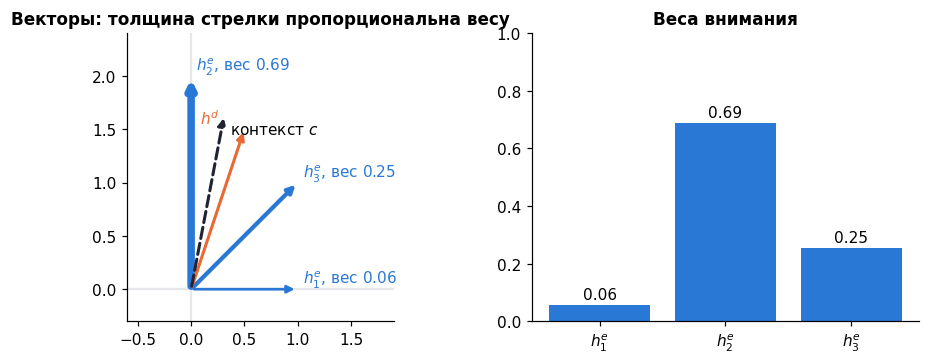

In [9]:
enc_states = np.array([[1.0, 0.0],      # h_1 кодировщика
                       [0.0, 2.0],      # h_2
                       [1.0, 1.0]])     # h_3
dec_state = np.array([0.5, 1.5])        # текущее состояние декодировщика

scores = enc_states @ dec_state                        # действие 1: скалярные произведения
weights = np.exp(scores) / np.exp(scores).sum()        # действие 2: softmax
context = weights @ enc_states                         # действие 3: взвешенная сумма
print("Оценки сходства:  ", scores)
print("Веса внимания:    ", np.round(weights, 3), " сумма =", round(weights.sum(), 3))
print("Контекстный вектор:", np.round(context, 3))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
ax = axes[0]
for j, (v, a) in enumerate(zip(enc_states, weights), start=1):
    ax.annotate("", xy=v, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", lw=1.5 + 5 * a, color=BLUE))
    ax.text(v[0] + 0.05, v[1] + 0.05, f"$h^e_{j}$, вес {a:.2f}", color=BLUE)
ax.annotate("", xy=dec_state, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", lw=2, color=ORANGE))
ax.text(dec_state[0] - 0.42, dec_state[1] + 0.05, "$h^d$", color=ORANGE)
ax.annotate("", xy=context, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", lw=2, color="#1f2430", ls="--"))
ax.text(context[0] + 0.05, context[1] - 0.18, "контекст $c$")
ax.set_xlim(-0.6, 1.9); ax.set_ylim(-0.3, 2.4); ax.set_aspect("equal"); ax.set_title("Векторы: толщина стрелки пропорциональна весу")
ax.axhline(0, color=GRID); ax.axvline(0, color=GRID)
axes[1].bar(["$h^e_1$", "$h^e_2$", "$h^e_3$"], weights, color=BLUE)
for j, a in enumerate(weights):
    axes[1].text(j, a + 0.02, f"{a:.2f}", ha="center")
axes[1].set_ylim(0, 1); axes[1].set_title("Веса внимания")
plt.show()

**Что видно на рисунке.** Состояние декодировщика направлено почти так же, как второе состояние кодировщика. Скалярное произведение с ним наибольшее (3.0), и после softmax оно получает вес 0.69. Третье состояние получает вес 0.25, первое 0.06. Контекстный вектор лежит между состояниями кодировщика ближе к тем, у которых вес больше.

### Модель с вниманием

Та же модель, что в части 3, с параметром `attention=True`. Кодировщик не меняется. Декодировщик на каждом шаге выполняет три действия из числового примера (метод `step` класса `Decoder`). Размер скрытого состояния и число эпох те же. Весов у модели с вниманием больше, потому что на вход GRU декодировщика дополнительно подаётся контекстный вектор.

In [10]:
set_seed()
model_attn = Seq2Seq(len(vocab), emb_dim=32, hidden=128, attention=True)
print("Весов в модели с вниманием:", sum(p.numel() for p in model_attn.parameters()))
hist_attn = train_seq2seq(model_attn, vocab, train_pairs, test_pairs, epochs=12)

Весов в модели с вниманием: 180323
эпоха 1: потери 0.313, точных совпадений на тесте 0.672
эпоха 2: потери 0.038, точных совпадений на тесте 0.912
эпоха 3: потери 0.023, точных совпадений на тесте 0.928
эпоха 4: потери 0.015, точных совпадений на тесте 0.928
эпоха 5: потери 0.021, точных совпадений на тесте 0.928
эпоха 6: потери 0.048, точных совпадений на тесте 0.910
эпоха 7: потери 0.022, точных совпадений на тесте 0.928
эпоха 8: потери 0.017, точных совпадений на тесте 0.928
эпоха 9: потери 0.046, точных совпадений на тесте 0.928
эпоха 10: потери 0.012, точных совпадений на тесте 0.928
эпоха 11: потери 0.013, точных совпадений на тесте 0.946
эпоха 12: потери 0.004, точных совпадений на тесте 1.000


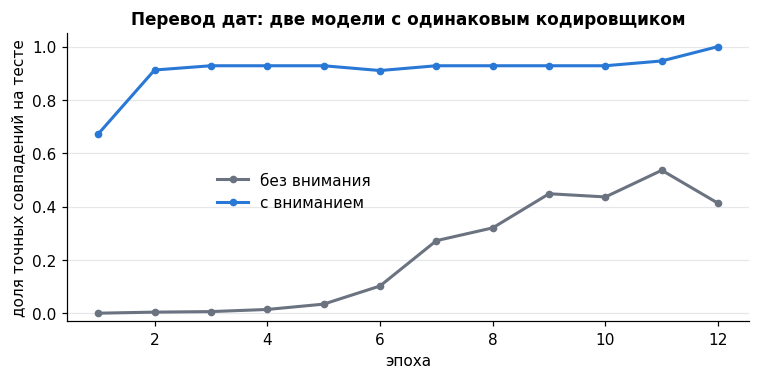

           вход без внимания с вниманием
 12 ноября 2026   2026-11-15  2026-11-12
     3 мая 1961   1961-05-02  1961-05-03
28 февраля 2000   2000-02-28  2000-02-28
1 сентября 1999   1999-09-09  1999-09-01
   17 июля 2031   2031-07-18  2031-07-17

Точных совпадений на тесте после 12 эпох: без внимания 0.412, с вниманием 1.000


In [11]:
fig, ax = plt.subplots(figsize=(8, 3.4))
ep = range(1, len(hist_plain) + 1)
ax.plot(ep, hist_plain, color=MUTED, lw=2, marker="o", ms=4, label="без внимания")
ax.plot(ep, hist_attn, color=BLUE, lw=2, marker="o", ms=4, label="с вниманием")
ax.set_xlabel("эпоха"); ax.set_ylabel("доля точных совпадений на тесте"); ax.set_ylim(-0.03, 1.05)
ax.set_title("Перевод дат: две модели с одинаковым кодировщиком"); ax.legend(frameon=False, loc="center left", bbox_to_anchor=(0.2, 0.45)); ax.grid(axis="y", color=GRID)
plt.show()

rows = []
for text in ("12 ноября 2026", "3 мая 1961", "28 февраля 2000", "1 сентября 1999", "17 июля 2031"):
    rows.append({"вход": text, "без внимания": translate(model_plain, vocab, text)[0], "с вниманием": translate(model_attn, vocab, text)[0]})
print(pd.DataFrame(rows).to_string(index=False))
print(f"\nТочных совпадений на тесте после 12 эпох: без внимания {hist_plain[-1]:.3f}, с вниманием {hist_attn[-1]:.3f}")

**Что видно на рисунке.** Обе модели имеют одинаковые кодировщик, размер скрытого состояния и число эпох. Модель с вниманием уже после второй эпохи переводит верно более 90 % дат и к двенадцатой эпохе доходит до 100 %. Модель без внимания за то же время доходит примерно до 40–50 %, и её кривая колеблется. В таблице видно, что ошибки модели без внимания приходятся на число дня. Модели с вниманием не нужно удерживать весь вход в одном векторе: на каждом шаге она заново обращается к нужным символам входа.

## Часть 6. Карты внимания

Веса $\alpha_{ij}$ можно показать таблицей: строка соответствует символу выхода, столбец символу входа, цвет клетки показывает вес. Такая таблица называется картой внимания. По ней видно, на какие символы входа модель опиралась при порождении каждого символа выхода.

При чтении карты нужно помнить, как вычисляются веса в этой реализации. Веса для шага $i$ считаются по состоянию декодировщика до этого шага, $h^{d}_{i-1}$. На первом шаге оно равно последнему состоянию кодировщика.

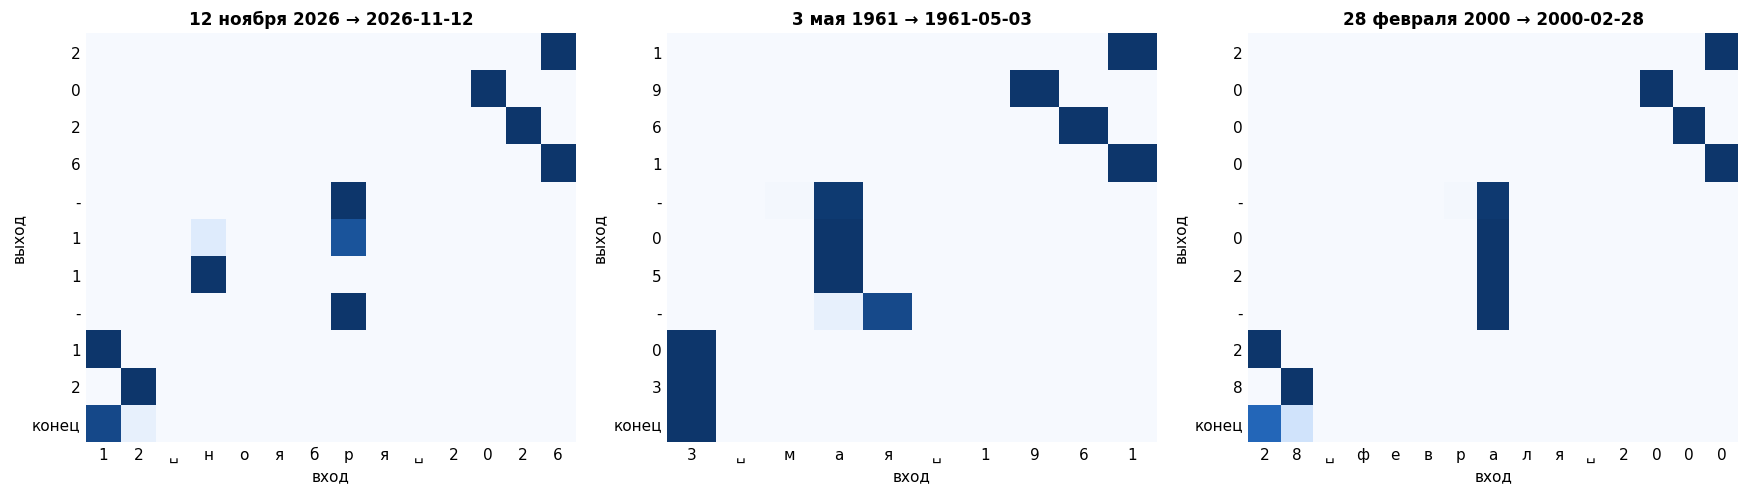

Для каждого символа выхода: символ входа с наибольшим весом
    выход «2»: вход «6» (позиция 14), вес 1.00
    выход «0»: вход «0» (позиция 12), вес 1.00
    выход «2»: вход «2» (позиция 13), вес 1.00
    выход «6»: вход «6» (позиция 14), вес 1.00
    выход «-»: вход «р» (позиция 8), вес 1.00
    выход «1»: вход «р» (позиция 8), вес 0.85
    выход «1»: вход «н» (позиция 4), вес 1.00
    выход «-»: вход «р» (позиция 8), вес 1.00
    выход «1»: вход «1» (позиция 1), вес 1.00
    выход «2»: вход «2» (позиция 2), вес 1.00
    выход «<eos>»: вход «1» (позиция 1), вес 0.91


In [12]:
examples = ["12 ноября 2026", "3 мая 1961", "28 февраля 2000"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, text in zip(axes, examples):
    out, attn = translate(model_attn, vocab, text)
    plot_attention(ax, attn, text, out, f"{text} → {out}")
fig.tight_layout()
plt.show()

out, attn = translate(model_attn, vocab, examples[0])
print("Для каждого символа выхода: символ входа с наибольшим весом")
for i, ch in enumerate(list(out) + ["<eos>"]):
    j = int(attn[i].argmax())
    print(f"    выход «{ch}»: вход «{examples[0][j]}» (позиция {j + 1}), вес {attn[i, j]:.2f}")

**Что видно на рисунке.** Каждая строка карты почти целиком сосредоточена в одной клетке: модель на каждом шаге смотрит на один-два символа входа.

- Четыре цифры года модель списывает с последних четырёх символов входа. На первом шаге вес стоит на последнем символе входа: состояние декодировщика в этот момент равно последнему состоянию кодировщика и больше всего похоже на него. Дальше внимание идёт по цифрам года слева направо.
- При порождении дефисов и двух цифр месяца внимание переходит на буквы названия месяца. Модель определяет номер месяца по одной-двум буквам, которые отличают его от других: «н» и «р» в слове «ноября», «а» в словах «мая» и «февраля».
- Две цифры дня модель списывает с первых символов входа. Для однозначного дня («3 мая») обе цифры выхода, ноль и тройка, смотрят на единственную цифру входа.
- На последнем шаге, когда выдаётся символ конца, внимание остаётся в начале входа.

Модель никто не учил, какие символы входа соответствуют символам выхода. Соответствие возникло само в ходе обучения переводу. Порядок частей при этом меняется: год стоит в конце входа и в начале выхода, и внимание это отражает.

## Часть 7. Длинные последовательности

Даты короткие, и длина входа почти не меняется. Чтобы увидеть узкое место, нужна задача с входами разной длины. Возьмём разворот строки: на входе случайная строка из цифр длиной от 3 до 20, на выходе та же строка в обратном порядке. Чтобы решить задачу, модель должна помнить каждую цифру входа и её место.

Обе модели одинакового размера (скрытое состояние из 64 чисел) обучаются 10 эпох на 6000 строк. Затем точность измеряется отдельно для каждой длины входа.

In [13]:
rev_train = make_pairs(reverse_pair, 6000, seed=1)
rev_test = make_pairs(reverse_pair, 300, seed=2)
rev_vocab = CharVocab(["0123456789"])
print("Примеры:", rev_train[:3])

rev_models, rev_hist = {}, {}
for name, attention in [("без внимания", False), ("с вниманием", True)]:
    set_seed()
    rev_models[name] = Seq2Seq(len(rev_vocab), emb_dim=32, hidden=64, attention=attention)
    rev_hist[name] = train_seq2seq(rev_models[name], rev_vocab, rev_train, rev_test, epochs=10, verbose=False)
    print(f"{name}: точных совпадений на тесте по эпохам {np.round(rev_hist[name], 2)}")

Примеры: [('9141777', '7771419'), ('317066907439150', '051934709660713'), ('080', '080')]
без внимания: точных совпадений на тесте по эпохам [0.04 0.13 0.18 0.22 0.22 0.27 0.3  0.3  0.32 0.34]
с вниманием: точных совпадений на тесте по эпохам [0.13 0.47 0.55 0.7  0.77 0.83 0.82 0.82 0.9  0.87]


              длина 4  длина 6  длина 8  длина 10  длина 12  длина 14  длина 16  длина 18  длина 20
без внимания     1.00     0.86     0.60      0.28      0.04      0.00      0.00      0.00      0.00
с вниманием      0.98     0.96     0.96      0.90      0.84      0.84      0.85      0.76      0.74


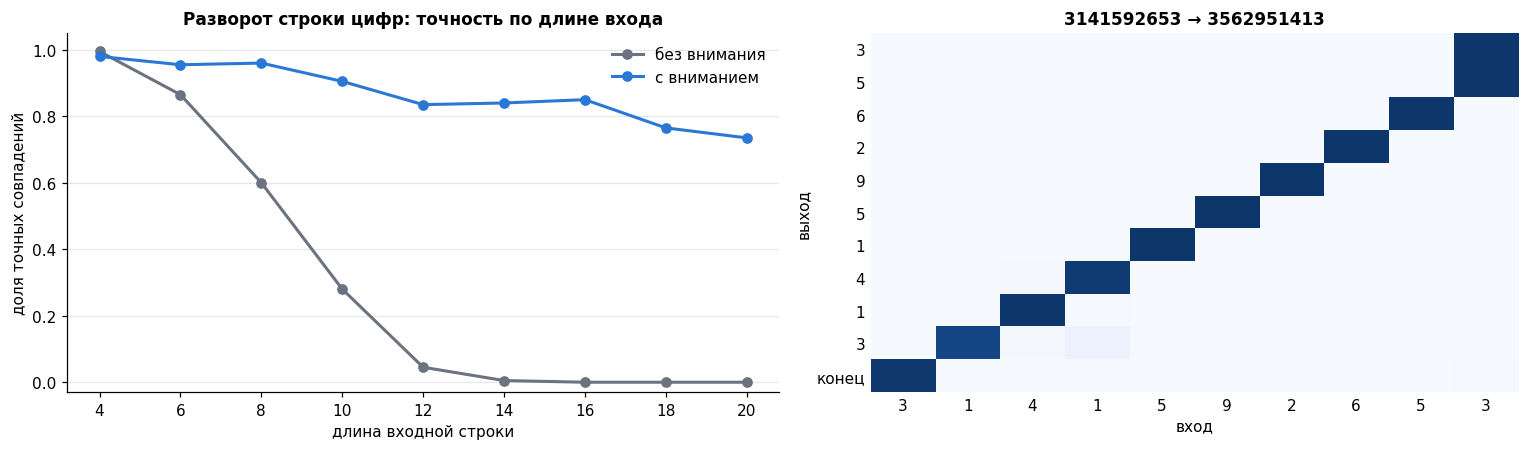

In [14]:
rev_lengths = [4, 6, 8, 10, 12, 14, 16, 18, 20]
by_length = {name: [exact_match(m, rev_vocab, make_pairs(reverse_pair, 200, seed=100 + L, length=L)) for L in rev_lengths]
             for name, m in rev_models.items()}
print(pd.DataFrame(by_length, index=[f"длина {L}" for L in rev_lengths]).round(2).T.to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1.1, 1]})
ax = axes[0]
ax.plot(rev_lengths, by_length["без внимания"], color=MUTED, lw=2, marker="o", label="без внимания")
ax.plot(rev_lengths, by_length["с вниманием"], color=BLUE, lw=2, marker="o", label="с вниманием")
ax.set_xticks(rev_lengths); ax.set_ylim(-0.03, 1.05); ax.set_xlabel("длина входной строки"); ax.set_ylabel("доля точных совпадений")
ax.set_title("Разворот строки цифр: точность по длине входа"); ax.legend(frameon=False); ax.grid(axis="y", color=GRID)
text = "3141592653"
out, attn = translate(rev_models["с вниманием"], rev_vocab, text)
plot_attention(axes[1], attn, text, out, f"{text} → {out}")
fig.tight_layout()
plt.show()

**Что видно на рисунке.** Слева показана доля точных совпадений в зависимости от длины входа. Модель без внимания справляется со строками из четырёх цифр, на восьми цифрах ошибается в 40 % случаев, строки длиннее двенадцати цифр не разворачивает совсем: 64 чисел контекстного вектора не хватает, чтобы запомнить длинную строку. Модель с вниманием теряет в точности гораздо медленнее и на строках из 20 цифр даёт около 75 % точных совпадений.

Справа показана карта внимания для строки из десяти цифр. Веса выстроились по побочной диагонали: первый символ выхода берётся из конца входа, последний из начала. Модель выучила правило «читать вход с конца», и длина входа для этого правила значения не имеет.

## Итог

- Модель seq2seq состоит из кодировщика, который читает вход, и декодировщика, который порождает выход по одному элементу.
- В модели без внимания весь вход передаётся декодировщику одним контекстным вектором. Это узкое место: чем длиннее вход, тем хуже результат.
- При обучении декодировщику подают правильный предыдущий символ (teacher forcing). При выводе он получает собственный предыдущий символ.
- Внимание строит для каждого шага декодировщика свой контекстный вектор: взвешенную сумму всех состояний кодировщика. Веса получаются из скалярных произведений и softmax.
- Карта внимания показывает, на какие элементы входа модель опиралась на каждом шаге.

Механизм внимания оказался настолько удачным, что следующая архитектура, трансформер, построена на нём целиком и обходится без рекуррентных сетей. Ей посвящена лекция 7.